<p style="font-size:11px;"><em><strong>Créditos</strong>: El contenido de este cuaderno ha sido tomado de varias fuentes, pero especialmente de <a href="https://github.com/fabsig/GPBoost">GPBoost (fabsig/GPBoost)</a>, <a href="https://htmlpreview.github.io/?https://github.com/fabsig/GPBoost/blob/master/examples/GPBoost_demo.html">GPBoost demo</a>, <a href="https://htmlpreview.github.io/?https://github.com/fabsig/GPBoost/blob/master/examples/European_GDP_spatial_grouped_data.html">European GDP spatial grouped data</a>, <a href="https://github.com/fabsig/GPBoost/blob/master/examples/python-guide/generalized_linear_Gaussian_process_mixed_effects_models.py">Python-guide de GPBoost</a>, <a href="https://arxiv.org/abs/2004.02653">Sigrist, F. (2022). Gaussian Process Boosting. <em>Journal of Machine Learning Research</em>, 23(232), 1-46</a>, y <a href="https://arxiv.org/abs/2105.08966">Sigrist, F. (2023). Latent Gaussian Model Boosting. <em>IEEE Transactions on Pattern Analysis and Machine Intelligence</em>, 45(2), 1894-1905</a>. El compilador se disculpa por cualquier omisión involuntaria y estaría encantado de agregar un reconocimiento.</em></p>

# GPBoost: Boosting de Árboles + Procesos Gaussianos

## Objetivos de aprendizaje

Al finalizar este notebook, el estudiante será capaz de:

- Entender por qué combinar *tree-boosting* (árboles de decisión potenciados) con un Proceso Gaussiano requiere una estrategia de estimación distinta a la de ajustar cada componente por separado.
- Explicar el modelo latente de GPBoost, $\mu = F(X) + Zb$, y el rol de cada término.
- Comprender la aproximación de Laplace y el algoritmo de estimación conjunta (LaGaBoost/GPBoost) que actualiza simultáneamente el ensamble de árboles $F(\cdot)$ y los hiperparámetros de covarianza del proceso gaussiano.
- Diferenciar con claridad GPBoost de: (a) un Proceso Gaussiano con media **lineal** (equivalente al Kriging Universal / Kriging con deriva externa), y (b) un enfoque **secuencial por fases** (ajustar un modelo no paramétrico y luego krigear sus residuos por separado).
- Implementar en Python, con la librería `gpboost`, un modelo con efectos aleatorios espaciales (GP) y agrupados (categóricos de alta cardinalidad), y comparar su desempeño contra las alternativas anteriores.

**Requisitos previos:** `15_GP.ipynb` — Procesos Gaussianos, kernel, Cholesky, y en particular la sección *Nota sobre modelos híbridos* donde se plantea el problema que este capítulo resuelve; `14_Kriging` — Kriging Ordinario y Universal, variogramas.

## Marco teórico

### 1. El problema de partida: ¿quién modela la tendencia y quién modela la autocorrelación?

En `15_GP.ipynb` (sección *Nota sobre modelos híbridos*) planteamos un problema muy concreto: cuando queremos predecir una variable espacial $y$ a partir de covariables $X$ (pendiente, geología, distancia a una vía, etc.) **y**, además, sabemos que hay una autocorrelación espacial residual que esas covariables no explican, tenemos que repartir el trabajo entre dos componentes:

$$y(\mathbf{s}) = \underbrace{F(X)}_{\text{tendencia / efecto de las covariables}} + \underbrace{Z(\mathbf{s})}_{\text{autocorrelación espacial residual}} + \underbrace{\varepsilon}_{\text{ruido}}$$

La pregunta de fondo es: **¿qué tan flexible dejamos que sea $F(X)$?** Y ahí aparecen tres estrategias, exactamente las que compara este capítulo:

1. **$F(X)$ lineal, ajustado junto con $Z(\mathbf{s})$** — esto es el **Kriging Universal** (o Kriging con deriva externa) que ya vimos en `14_Kriging`, y su versión en el lenguaje de Procesos Gaussianos es un **GP con media lineal**. Es simple y estable, pero solo puede capturar relaciones **lineales** entre las covariables y la respuesta.
2. **$F(X)$ no paramétrico (árboles, Random Forest), ajustado *primero*, y luego $Z(\mathbf{s})$ ajustado *por separado* sobre los residuos** — esto es el enfoque clásico de **regresión-kriging en dos fases** (y es la solución "secuencial" que ya mencionamos en `15_GP.ipynb`). Es más flexible que la opción 1, pero, como veremos, tiene un problema de fondo: las dos fases no "se hablan" entre sí.
3. **$F(X)$ no paramétrico, estimado *conjuntamente* con $Z(\mathbf{s})$ en el mismo proceso de optimización** — esto es exactamente lo que hace **GPBoost**. Es la respuesta formal, con garantías estadísticas, al problema de "competencia de varianza" entre un modelo no lineal flexible y un GP que planteamos en el capítulo anterior.

### 2. Por qué las opciones 1 y 2 no son ideales

**Opción 1 (GP con media lineal / Kriging Universal).** El término $F(X) = X\beta$ es una combinación lineal de las covariables. Si la relación real entre, por ejemplo, la pendiente del terreno y la susceptibilidad a un deslizamiento es fuertemente no lineal (un umbral, una curva en forma de S, una interacción entre dos variables), un modelo lineal simplemente **no puede representarla**, sin importar cuántos datos tengamos. El GP puede compensar parcialmente absorbiendo parte de ese patrón como si fuera "autocorrelación espacial" (si las covariables están correlacionadas con la posición), pero eso es un parche, no una solución: mezcla, en la parte $Z(\mathbf{s})$, algo que en realidad es un efecto de las covariables mal modelado.

**Opción 2 (secuencial: ajustar $F(X)$ primero con árboles, luego krigear los residuos).** Este enfoque —a veces llamado *regression-kriging* o, informalmente, "RF-Kriging"— sí permite que $F(X)$ sea no lineal. Pero tiene tres problemas concretos:

- **Los residuos de la primera fase no son independientes.** Todo algoritmo de *boosting* o Random Forest asume, implícita o explícitamente, que las observaciones son independientes entre sí dado $X$. Si hay autocorrelación espacial real en $y$, esa autocorrelación *sigue estando* en los residuos de la primera fase (por eso los vamos a krigear después). El árbol de la primera fase se entrenó ignorando esa dependencia, lo cual puede sesgar tanto la estructura del árbol como la estimación de su incertidumbre.
- **El árbol puede "robarse" señal espacial.** Si alguna covariable de $X$ está correlacionada con la ubicación (algo extremadamente común en datos geoespaciales: la elevación, la distancia a la costa, el tipo de suelo, todas varían suavemente en el espacio), un modelo de árboles suficientemente flexible puede terminar ajustando parte del patrón espacial *a través* de esas covariables, en lugar de dejárselo al GP. El resultado: los residuos que le pasamos al GP en la segunda fase tienen **menos** señal espacial de la que realmente existe, y el GP subestima la varianza espacial verdadera ($\sigma^2$) y sobreestima el nugget/ruido ($\sigma_n^2$). Verificaremos esto con números reales en el ejemplo de abajo.
- **No hay propagación de incertidumbre entre fases.** El error estándar de las predicciones finales debería reflejar la incertidumbre tanto de $F(X)$ como de $Z(\mathbf{s})$, pero al estimarlos por separado, la incertidumbre de la primera fase generalmente no se combina correctamente con la de la segunda.

### 3. El modelo de GPBoost

GPBoost resuelve el problema anterior proponiendo un **modelo Gaussiano latente no paramétrico** (Sigrist, 2022, 2023). El parámetro de interés $\mu$ (para datos Gaussianos, directamente la media de $y$) se modela como:

$$\mu = F(X) + Zb, \qquad b \sim \mathcal{N}(0, \Sigma)$$

donde:

- $F(\cdot)$ es un **ensamble de árboles de decisión** (como en LightGBM/XGBoost) — no lineal, no paramétrico, capaz de capturar interacciones y umbrales sin que el usuario tenga que especificarlos.
- $b$ es un vector de **efectos latentes Gaussianos**: puede ser un Proceso Gaussiano espacial (como los de `15_GP` y `14_Kriging`), un efecto aleatorio agrupado (una categoría con muchos niveles, p. ej. "municipio" o "cuenca"), o una combinación de ambos.
- $Z$ es la matriz que conecta esos efectos latentes con las observaciones (para un GP espacial, $Z = I$; para un efecto agrupado, $Z$ es una matriz de incidencia 0/1 que indica a qué grupo pertenece cada observación).
- $\Sigma = \Sigma(\theta)$ es la matriz de covarianza de $b$, parametrizada por hiperparámetros $\theta$ — para un GP, esto es exactamente el kernel que vimos en `15_GP.ipynb` (Matérn, RBF, etc.) con su rango y varianza.

Para datos Gaussianos (regresión continua), el modelo completo se escribe de forma equivalente como:

$$y = F(X) + Zb + \xi, \qquad \xi \sim \mathcal{N}(0, \sigma_n^2 I)$$

que es, formalmente, **el mismo modelo que un GP con media $F(X)$** — la única pero crucial diferencia es que $F(X)$ ya no está restringido a ser lineal. Para verosimilitudes no Gaussianas (clasificación, conteos), GPBoost usa una función de enlace $G(\cdot)$:

$$y \sim p(y \mid m), \qquad m = G\big(F(X) + Zb\big)$$

generalizando así, en la misma familia, tanto los **Modelos Lineales Mixtos Generalizados (GLMM)** como los **Procesos Gaussianos** — sustituyendo únicamente la parte lineal $X\beta$ de esos modelos clásicos por un ensamble de árboles $F(X)$.

### 4. ¿Cómo se estima esto conjuntamente? La verosimilitud marginal y la aproximación de Laplace

La dificultad técnica de este modelo es que $b$ es un vector latente (no observado) de posiblemente miles de dimensiones. Para entrenar el modelo necesitamos la **verosimilitud marginal**, que integra sobre todos los valores posibles de $b$:

$$p(y \mid F, \theta, \xi) = \int p(y \mid \mu, \xi)\, p(b \mid \theta)\, db, \qquad \mu = F(X) + Zb$$

Si $y$ es Gaussiano, esta integral tiene solución exacta (es la misma matemática de un GP estándar que vimos en `15_GP.ipynb`: media y covarianza posteriores en forma cerrada). Si $y$ seguisiera una distribución no Gaussiana (Bernoulli, Poisson), la integral no tiene solución analítica y se aproxima usando la **aproximación de Laplace**: se encuentra la moda $\tilde{b}$ de $p(y \mid \mu, \xi)\, p(b \mid \theta)$ mediante el método de Newton, y se aproxima la verosimilitud marginal con una Gaussiana centrada en esa moda:

$$p(y \mid F, \theta, \xi) \approx p(y \mid \tilde{\mu}, \xi)\, p(\tilde{b} \mid \theta)\, \det\!\left(Z^T \tilde{W} Z + \Sigma^{-1}\right)^{-1/2} (2\pi)^{m/2}$$

donde $\tilde{W}$ es una matriz diagonal con las segundas derivadas de la log-verosimilitud evaluadas en la moda. No es necesario memorizar esta fórmula: lo importante es que, a partir de ella, se puede calcular tanto el **riesgo** que queremos minimizar,

$$R(F, \theta, \xi) = -\log p(y \mid F, \theta, \xi),$$

como su **gradiente respecto a $F$** y su **gradiente respecto a $\theta$** — y esos dos gradientes son exactamente lo que el algoritmo de entrenamiento necesita.

### 5. El algoritmo LaGaBoost / GPBoost: estimación conjunta, no secuencial

Aquí está el corazón conceptual del capítulo. En vez de (a) estimar $F(X)$ hasta el final y luego (b) estimar $\theta$ una sola vez con los residuos —como en el enfoque secuencial de la Opción 2—, GPBoost **alterna** ambos pasos dentro del mismo bucle de entrenamiento, ronda tras ronda de *boosting*:

> **Algoritmo (versión intuitiva).** Se repite, para cada ronda $m = 1, \dots, M$:
>
> 1. **Paso GP:** con el ensamble de árboles $F_{m-1}(\cdot)$ que se tiene hasta el momento (fijo), se actualizan los hiperparámetros de covarianza $\theta$ (p. ej. el rango y la varianza del kernel Matérn) resolviendo un problema de optimización convexa (equivalente a un paso de *Fisher scoring*).
> 2. **Paso árbol:** con esos hiperparámetros $\theta$ ya actualizados (fijos), se calcula el **gradiente funcional** de la verosimilitud respecto a $F$ —es decir, "¿en qué dirección debería moverse $F$ para explicar mejor lo que el GP actual todavía no explica?"— y se ajusta un **árbol pequeño** $f_m(\cdot)$ que aproxima ese gradiente (esto es exactamente lo que hace cualquier algoritmo de *gradient boosting*, como LightGBM).
> 3. **Actualización:** $F_m(\cdot) = F_{m-1}(\cdot) + \nu \, f_m(\cdot)$, con $\nu$ una tasa de aprendizaje pequeña (igual que en cualquier boosting).

La versión formal de este algoritmo (Sigrist, 2022, 2023) es:

$$f_m(\cdot) = \operatorname*{argmin}_{f \in \mathcal{S}} \left\| -\frac{\partial L^{A}(y, F_{m-1}, \theta_m, \xi_m)}{\partial F} - f \right\|^2$$

es decir, el árbol de la ronda $m$ es el que mejor aproxima, en mínimos cuadrados, el **negativo del gradiente funcional** de la verosimilitud aproximada — igual que en *gradient boosting* clásico, solo que aquí el gradiente ya "sabe" acerca del efecto espacial $Zb$ porque se calculó teniendo en cuenta $\theta_m$, recién actualizado en el paso 1.

**Esta alternancia es la diferencia esencial frente al enfoque secuencial.** En la Opción 2, el árbol nunca se entera de que existe un GP: se entrena una sola vez, de forma totalmente ciega a la estructura espacial, y el GP se ajusta después sobre lo que sobró. En GPBoost, cada árbol nuevo se ajusta *sabiendo* cuál es el estado actual del componente espacial, y cada actualización del GP se hace *sabiendo* cuál es el estado actual de los árboles. Ambas partes se corrigen mutuamente en cada ronda, hasta converger a un óptimo conjunto del riesgo $R(F, \theta, \xi)$.

### 6. Tipos de efectos latentes: agrupados, espaciales, y combinados

El término $Zb$ del modelo no está restringido a ser un único Proceso Gaussiano espacial. `gpboost` admite:

- **Efectos aleatorios agrupados** (`group_data=`): para variables categóricas, incluyendo aquellas de **alta cardinalidad** (muchas categorías, p. ej. cientos de municipios) donde meterlas directamente como *dummies* en un árbol sería ineficiente y propenso a sobreajuste. En vez de eso, cada categoría recibe un efecto aleatorio $b_g \sim \mathcal{N}(0, \tau^2)$ que se regulariza hacia cero (encogimiento, *shrinkage*), igual que en un modelo mixto clásico.
- **Procesos Gaussianos** (`gp_coords=` + `cov_function=`): exactamente los kernels espaciales de `15_GP.ipynb` y `14_Kriging` (Matérn, exponencial, gaussiano/RBF).
- **Combinaciones de ambos**: por ejemplo, un efecto aleatorio de país (agrupado) *más* un Proceso Gaussiano de coordenadas dentro de ese país, como en el ejemplo de PIB regional europeo de la librería GPBoost, donde el ingreso de una región depende tanto de efectos específicos de cada país (institucionales, monetarios) como de una autocorrelación espacial suave entre regiones vecinas, independientemente de las fronteras nacionales.

Esta flexibilidad convierte a GPBoost en una herramienta natural para dos problemas típicos de la ciencia de datos geoespacial que, en los capítulos anteriores, tratamos por separado: la **alta cardinalidad categórica** (que vimos con modelos jerárquicos en `12_Jerarquicos`) y la **autocorrelación espacial continua** (Kriging, GP, LGCP).

### 7. Resumen comparativo

| | GP con media lineal<br>(Kriging Universal / deriva externa) | Secuencial<br>(árboles → residuos → krigeados) | **GPBoost**<br>(estimación conjunta) |
|:---|:---|:---|:---|
| **Forma de $F(X)$** | Lineal ($X\beta$) | No paramétrica (árboles/RF), fija tras la 1ª fase | No paramétrica (árboles), actualizada cada ronda |
| **¿Captura no linealidades e interacciones en $X$?** | No | Sí | Sí |
| **¿$F$ y $\theta$ "se hablan" durante el ajuste?** | N/A (un solo paso conjunto, pero $F$ es rígido) | No — dos fases independientes | Sí — se alternan en cada ronda de boosting |
| **Riesgo de sesgo en $\hat\theta$ (rango, varianza espacial)** | Bajo, pero $F$ mal especificado sesga las predicciones | Alto si $X$ está correlacionada con la ubicación | Bajo — el objetivo conjunto lo evita |
| **Propagación de incertidumbre** | Correcta (un solo modelo) | Aproximada (se pierde entre fases) | Correcta (un solo objetivo conjunto) |
| **Equivalente clásico** | Kriging Universal / KED | Regression-kriging en 2 fases | Sin equivalente clásico directo |

En el ejemplo siguiente comprobamos, con datos simulados donde conocemos la verdad, cada una de estas afirmaciones con números reales.

## Ejemplo práctico: comparando las tres estrategias con datos simulados

Usamos datos **simulados** a propósito: así conocemos la verdad (la función no lineal real, el rango y la varianza reales del proceso espacial) y podemos verificar, con números, cuál de las tres estrategias la recupera mejor. Simulamos:

- Una covariable $X = (X_1, X_2)$ **independiente de la ubicación**, con un efecto **claramente no lineal** sobre $y$: $f(X_1, X_2) = 2\sin(1.3\,X_1) + 0.3\,X_2^2 - 1.5$.
- Un efecto espacial $Z(\mathbf{s})$ generado con un Proceso Gaussiano de covarianza Matérn ($\nu=1.5$), varianza $\sigma^2=1.0$ y rango $\rho=2.0$ — exactamente como en `15_GP.ipynb` y `14_Kriging`.
- Ruido de medición $\varepsilon \sim \mathcal{N}(0, 0.3^2)$.

$$y = f(X_1, X_2) + Z(\mathbf{s}) + \varepsilon$$

In [1]:
import numpy as np
import gpboost as gpb
import lightgbm as lgb
from scipy.spatial.distance import cdist
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 1000

# Covariable con efecto NO LINEAL, independiente de la ubicación
X = rng.uniform(-3, 3, size=(n, 2))


def f_true(X):
    return 2 * np.sin(1.3 * X[:, 0]) + 0.3 * (X[:, 1] ** 2) - 1.5


# Coordenadas espaciales y efecto GP (kernel Matern, nu=1.5)
coords = rng.uniform(0, 10, size=(n, 2))


def matern_cov(coords, rho=2.0, sigma2=1.0):
    D = cdist(coords, coords)
    Ds = np.sqrt(3) * D / rho
    return sigma2 * (1 + Ds) * np.exp(-Ds)


K = matern_cov(coords) + np.eye(n) * 1e-6
L_chol = np.linalg.cholesky(K)  # descomposicion de Cholesky, ver 15_GP.ipynb
b_spatial = L_chol.dot(rng.standard_normal(n))

noise_sd = 0.3
y = f_true(X) + b_spatial + rng.normal(0, noise_sd, n)

# Division train / test
idx = rng.permutation(n)
n_train = 800
train_idx, test_idx = idx[:n_train], idx[n_train:]
X_train, X_test = X[train_idx], X[test_idx]
coords_train, coords_test = coords[train_idx], coords[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print(f"Observaciones de entrenamiento: {n_train}, de prueba: {n - n_train}")

C:\Users\edier\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Observaciones de entrenamiento: 800, de prueba: 200


### Modelo A: Proceso Gaussiano con media lineal (~ Kriging Universal)

Ajustamos $\mu = X\beta + Zb$ — el GP recibe la covariable únicamente a través de un término **lineal**. Este es el análogo directo, en el lenguaje de Procesos Gaussianos, del Kriging Universal / Kriging con deriva externa de `14_Kriging`.

In [2]:
gp_model_a = gpb.GPModel(gp_coords=coords_train, cov_function="matern",
                          cov_fct_shape=1.5, likelihood="gaussian")

X_train_design = np.column_stack([np.ones(len(X_train)), X_train])  # intercepto + X (lineal)
X_test_design = np.column_stack([np.ones(len(X_test)), X_test])

gp_model_a.fit(y=y_train, X=X_train_design)
pred_a = gp_model_a.predict(gp_coords_pred=coords_test, X_pred=X_test_design,
                             predict_var=True, predict_response=True)

rmse_a = np.sqrt(mean_squared_error(y_test, pred_a["mu"]))
print(f"RMSE (GP con media lineal / Kriging Universal): {rmse_a:.4f}")

RMSE (GP con media lineal / Kriging Universal): 1.6101


### Modelo B: enfoque secuencial (árboles → residuos → kriging)

Primero ajustamos un modelo de *gradient boosting* estándar (LightGBM, **sin ninguna información espacial**) sobre $X$. Luego, calculamos los residuos de entrenamiento y ajustamos un GP **separado** sobre esos residuos — exactamente el flujo de trabajo de "regression-kriging" en dos fases.

In [3]:
# Fase 1: boosting puro sobre X (sin coordenadas)
train_set_b = lgb.Dataset(X_train, y_train)
params_b = {"objective": "regression", "learning_rate": 0.05, "max_depth": 3, "verbose": -1}
bst_b = lgb.train(params_b, train_set_b, num_boost_round=200)

resid_train_b = y_train - bst_b.predict(X_train)

# Fase 2: kriging de los residuos (por separado, sin retroalimentacion a la fase 1)
gp_model_b = gpb.GPModel(gp_coords=coords_train, cov_function="matern",
                          cov_fct_shape=1.5, likelihood="gaussian")
gp_model_b.fit(y=resid_train_b)
pred_resid_b = gp_model_b.predict(gp_coords_pred=coords_test, predict_var=True, predict_response=True)

pred_b = bst_b.predict(X_test) + pred_resid_b["mu"]
rmse_b = np.sqrt(mean_squared_error(y_test, pred_b))
print(f"RMSE (secuencial: boosting + kriging de residuos): {rmse_b:.4f}")

RMSE (secuencial: boosting + kriging de residuos): 0.5262


### Modelo C: GPBoost (estimación conjunta)

Un solo modelo: `gpb.train()` recibe tanto el `Dataset` de covariables como el `GPModel` con las coordenadas, y entrena ambos **juntos**, alternando los dos pasos descritos en la sección teórica (actualizar $\theta$, luego ajustar un árbol al gradiente funcional).

In [4]:
gp_model_c = gpb.GPModel(gp_coords=coords_train, cov_function="matern",
                          cov_fct_shape=1.5, likelihood="gaussian")

train_set_c = gpb.Dataset(X_train, y_train)
params_c = {"objective": "regression_l2", "learning_rate": 0.05, "max_depth": 3, "verbose": -1}

bst_c = gpb.train(params=params_c, train_set=train_set_c,
                   gp_model=gp_model_c, num_boost_round=200)

pred_c = bst_c.predict(data=X_test, gp_coords_pred=coords_test,
                        predict_var=True, pred_latent=False)

rmse_c = np.sqrt(mean_squared_error(y_test, pred_c["response_mean"]))
print(f"RMSE (GPBoost, estimacion conjunta): {rmse_c:.4f}")

RMSE (GPBoost, estimacion conjunta): 0.4071


### Comparación de resultados

Con la misma simulación (recordemos: covariable con efecto claramente no lineal, GP espacial con $\sigma^2=1.0$ y $\rho=2.0$ verdaderos), los tres modelos obtienen:

In [5]:
resultados = {
    "A: GP media lineal (Universal Kriging)": rmse_a,
    "B: Boosting + kriging de residuos (secuencial)": rmse_b,
    "C: GPBoost (estimacion conjunta)": rmse_c,
}

print("=== RMSE en el conjunto de prueba ===")
for nombre, rmse in resultados.items():
    print(f"{nombre}: {rmse:.4f}")

=== RMSE en el conjunto de prueba ===
A: GP media lineal (Universal Kriging): 1.6101
B: Boosting + kriging de residuos (secuencial): 0.5262
C: GPBoost (estimacion conjunta): 0.4071


Como se esperaba de la teoría: el **modelo A** (media lineal) tiene el peor desempeño, porque no puede representar la forma de $f(X_1, X_2)$ —sin importar cuántos datos le demos, seguirá cometiendo el mismo error sistemático—. El **modelo B** (secuencial) mejora sustancialmente al dejar que los árboles capturen la no linealidad, pero **el modelo C (GPBoost) sigue siendo mejor**, porque la retroalimentación entre el árbol y el GP en cada ronda evita que ninguno de los dos componentes quede mal ajustado por el otro.

¿Por qué exactamente es mejor el modelo C? Comparemos los **hiperparámetros de covarianza estimados** —el rango y la varianza espacial verdaderos son $\rho = 2.0$ y $\sigma^2 = 1.0$— entre el modelo B (secuencial) y el modelo C (GPBoost):

In [6]:
print("=== Modelo B (secuencial): hiperparametros del GP sobre los residuos ===")
gp_model_b.summary()

print()
print("=== Modelo C (GPBoost, conjunto): hiperparametros del GP ===")
gp_model_c.summary()

=== Modelo B (secuencial): hiperparametros del GP sobre los residuos ===
Model summary:
Nb. observations: 800
 Log-lik     AIC     BIC
 -600.64 1207.29 1221.34
-----------------------------------------------------
Covariance parameters (random effects):
           Param.  Std. err.
Error_var  0.1891     0.0111
GP_var     0.7248     0.2235
GP_range   1.8259     0.2905

=== Modelo C (GPBoost, conjunto): hiperparametros del GP ===
Model summary:
Nb. observations: 800
Covariance parameters (random effects):
           Param.  Std. err.
Error_var  0.0281     0.0020
GP_var     1.0066     0.3106
GP_range   1.9817     0.2570


Fíjense en `GP_var` (la varianza espacial $\sigma^2$, verdadera = 1.0) y en `Error_var` (el nugget/ruido $\sigma_n^2$, verdadero = $0.3^2 = 0.09$). El modelo B, al haber ajustado los árboles *antes* y de forma ciega a la estructura espacial, típicamente **subestima** `GP_var` y **sobreestima** `Error_var`: parte de la señal espacial real quedó absorbida por los árboles de la primera fase (o simplemente diluida en un residuo que ya no es un GP "limpio"), y lo que le queda al GP de la segunda fase parece, incorrectamente, más ruidoso y menos espacialmente estructurado de lo que en verdad es. El modelo C, en cambio, recupera valores mucho más cercanos a los verdaderos $\rho=2.0$ y $\sigma^2=1.0$ — exactamente la ventaja que predice la teoría de la Sección 2: la estimación conjunta evita que el componente no paramétrico "se robe" señal espacial que le corresponde al GP.

### ¿Recupera GPBoost la forma no lineal real de $F(X)$?

Podemos extraer, del modelo C, únicamente la parte de árboles $\hat{F}(X)$ (sin el efecto espacial) usando `pred_latent=True`, y compararla contra la función verdadera $f(X_1, X_2=0)$.

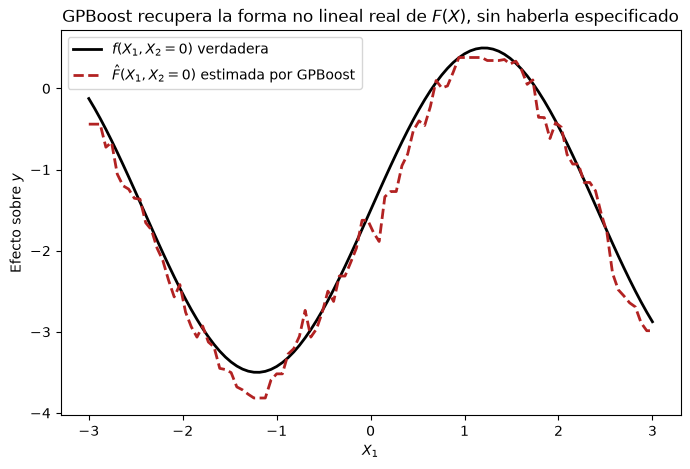

In [7]:
x1_grid = np.linspace(-3, 3, 100)
X_grid = np.column_stack([x1_grid, np.zeros(100)])  # variamos X1, fijamos X2 = 0
coords_grid = np.tile(coords_train.mean(axis=0), (100, 1))  # ubicacion arbitraria (no afecta la parte fija)

pred_latent = bst_c.predict(data=X_grid, gp_coords_pred=coords_grid, pred_latent=True)
F_hat = pred_latent["fixed_effect"]
f_verdadera = f_true(X_grid)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x1_grid, f_verdadera, label="$f(X_1, X_2=0)$ verdadera", lw=2, color="black")
ax.plot(x1_grid, F_hat, label=r"$\hat{F}(X_1, X_2=0)$ estimada por GPBoost", lw=2, ls="--", color="firebrick")
ax.set_xlabel("$X_1$")
ax.set_ylabel("Efecto sobre $y$")
ax.set_title("GPBoost recupera la forma no lineal real de $F(X)$, sin haberla especificado")
ax.legend()
plt.show()

El ensamble de árboles recupera razonablemente bien la forma sinusoidal de la función real **sin que nosotros le hayamos dicho su forma funcional** —ni lineal, ni cuadrática, ni ninguna otra—, algo que un GP con media lineal (modelo A) jamás podría lograr.

## Efectos agrupados y espaciales combinados

Muchos problemas geoespaciales tienen **ambas** fuentes de dependencia a la vez: una variable categórica de alta cardinalidad (país, municipio, cuenca) *y* una autocorrelación espacial continua dentro de —y a través de— esas categorías. El ejemplo de PIB regional europeo de la librería GPBoost combina exactamente esto: el ingreso de una región depende de efectos propios de cada país (institucionales, monetarios, fiscales) *más* de una autocorrelación espacial suave entre regiones geográficamente cercanas, que no respeta las fronteras administrativas.

En `gpboost`, esto se especifica pasando **ambos** argumentos al mismo `GPModel`: `group_data=` para el efecto agrupado y `gp_coords=` para el efecto espacial. Lo ilustramos con un ejemplo sintético pequeño (15 grupos, con un efecto propio por grupo, más una covariable con efecto no lineal):

In [8]:
rng2 = np.random.default_rng(7)
n2 = 400

grupo = rng2.integers(0, 15, n2).astype(str)  # p. ej., 15 "paises"
coords2 = rng2.uniform(0, 10, size=(n2, 2))
X2 = rng2.uniform(-2, 2, size=(n2, 1))

efecto_grupo = {g: rng2.normal(0, 1.2) for g in set(grupo)}
b_grupo = np.array([efecto_grupo[g] for g in grupo])

y2 = 2 * np.sin(X2[:, 0]) + b_grupo + rng2.normal(0, 0.2, n2)

gp_model_comb = gpb.GPModel(group_data=grupo, gp_coords=coords2,
                             cov_function="matern", cov_fct_shape=1.5,
                             likelihood="gaussian")

train_set_comb = gpb.Dataset(X2, y2)
bst_comb = gpb.train(params={"objective": "regression_l2", "learning_rate": 0.1,
                              "max_depth": 2, "verbose": -1},
                      train_set=train_set_comb, gp_model=gp_model_comb, num_boost_round=100)

gp_model_comb.summary()

Model summary:
Nb. observations: 400
Nb. groups: 15 (Group_1)
Covariance parameters (random effects):
           Param.     Std. err.
Error_var  0.0489  5.200000e-03
Group_1    2.7715  1.012700e+00
GP_var     0.0000  3.800000e-03
GP_range   0.4958  2.921056e+06


El resumen muestra un parámetro de varianza separado para el efecto de grupo (`Group_1`) y otro para el proceso espacial (`GP_var`, `GP_range`) — ambos estimados **conjuntamente** con el ensamble de árboles que captura el efecto no lineal de $X$.

## Más allá de la regresión: verosimilitudes no Gaussianas (LaGaBoost)

Todo lo anterior asumió una respuesta continua Gaussiana. El marco general de Sigrist (2023) —el algoritmo **LaGaBoost**, del cual GPBoost es el caso particular Gaussiano— permite exactamente la misma idea para **cualquier** distribución de la familia exponencial, usando la aproximación de Laplace de la Sección 4 del marco teórico:

$$y \sim p(y \mid m), \qquad m = G\big(F(X) + Zb\big)$$

Por ejemplo, `likelihood="bernoulli_probit"` permite modelar una **ocurrencia binaria** (¿hubo o no un deslizamiento en esta ladera?) con un efecto espacial latente y un ensamble de árboles para las covariables geotécnicas — conceptualmente muy cercano al **LGCP** de `17_LGCP.Rmd`, pero para clasificación binaria en lugar de conteo de eventos puntuales, y con $F(X)$ no paramétrico en lugar de un predictor lineal. Otras opciones incluyen `"poisson"` (conteos) y `"gamma"` (variables positivas asimétricas). La sintaxis es idéntica a la de los ejemplos anteriores; solo cambia el argumento `likelihood` del `GPModel`.

## Actividades

1. **Efecto del tamaño de muestra.** Repite el experimento de la sección *Ejemplo práctico* con $n = 200$ y con $n = 3000$ observaciones. ¿La ventaja de GPBoost sobre el enfoque secuencial (modelo B) se hace más grande o más pequeña al aumentar los datos? Relaciona tu respuesta con la Sección 2 del marco teórico.

2. **Covariables correlacionadas con la ubicación.** Modifica la simulación para que $X_1$ esté correlacionada con las coordenadas espaciales (por ejemplo, `X1 = coords[:,0]/3 + ruido`). Vuelve a comparar los tres modelos. ¿El desempeño del modelo B (secuencial) empeora respecto al caso donde $X$ es independiente de la ubicación? ¿Por qué, según la Sección 2?

3. **Kernels y tasa de aprendizaje.** Cambia `cov_function` de `"matern"` a `"exponential"` y `"gaussian"` (recordando la Sección *Correspondencia entre kernels y modelos de variograma* de `15_GP.ipynb`), y varía `learning_rate` en `params_c` entre 0.01, 0.1 y 0.3. Grafica el RMSE de GPBoost en función de estas combinaciones.

4. **Efectos agrupados de alta cardinalidad.** Aumenta el número de grupos del ejemplo combinado a 100. Compara el desempeño de incluir el grupo como *dummy variables* directamente en $X$ (para que lo procesen los árboles) contra dejarlo como efecto aleatorio en `group_data=`. ¿Cuál escala mejor y por qué?

5. **Verosimilitud no Gaussiana.** Usando la función `simulate_response_variable()` del [script de ejemplo de GPBoost](https://github.com/fabsig/GPBoost/blob/master/examples/python-guide/generalized_linear_Gaussian_process_mixed_effects_models.py), simula datos binarios (`likelihood="bernoulli_probit"`) con un efecto espacial, y ajusta un modelo GPBoost de clasificación. Compara sus predicciones de probabilidad con las de una regresión logística con covariables espaciales lineales.

## Recursos adicionales

### Documentación oficial
- [GPBoost (repositorio principal)](https://github.com/fabsig/GPBoost)
- [Ejemplos en Python](https://github.com/fabsig/GPBoost/tree/master/examples/python-guide)
- [Demo interactivo de GPBoost](https://htmlpreview.github.io/?https://github.com/fabsig/GPBoost/blob/master/examples/GPBoost_demo.html)
- [Ejemplo de PIB regional europeo (efectos agrupados + GP espacial)](https://htmlpreview.github.io/?https://github.com/fabsig/GPBoost/blob/master/examples/European_GDP_spatial_grouped_data.html)

### Lecturas recomendadas
- Sigrist, F. (2022). [Gaussian Process Boosting](https://arxiv.org/abs/2004.02653). *Journal of Machine Learning Research*, 23(232), 1-46.
- Sigrist, F. (2023). [Latent Gaussian Model Boosting](https://ieeexplore.ieee.org/document/9759834). *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 45(2), 1894-1905.
- Kündig, P. & Sigrist, F. (2024). [Iterative Methods for Vecchia-Laplace Approximations for Latent Gaussian Process Models](https://www.tandfonline.com/doi/full/10.1080/01621459.2024.2410004). *Journal of the American Statistical Association*.
- Pinheiro, J. & Bates, D. (2006). *Mixed-Effects Models in S and S-PLUS*. Springer.
- Ke, G. et al. (2017). [LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://papers.nips.cc/paper/6907-lightgbm-a-highly-efficient-gradient-boosting-decision-tree). *Advances in Neural Information Processing Systems*, 30.